# Notebook 02 — Cleaning, Harmonisation, Leakage-Aware Splitting and Preprocessing



| Finding in NB01 | Consequence | Action here |
|---|---|---|
| NSL-KDD loaded **297,034 rows = exactly 2 × 148,517** | The Kaggle archive extracted twice; `rglob` matched every file twice | §2 de-duplicates the *file list* by SHA-256 before reading |
| UNSW-NB15 loaded **2,540,047 = official + 3** | Parts 1-3 carry a header line that was read as data | §2 drops rows that fail numeric coercion on `dur` |
| CIC has **8 constant columns** and **10 column pairs at r = 1.000** | 18 columns carry zero unique information | §3 detects and drops them by value-hash rather than by hard-coded name |
| CIC has **4,376 infinite** cells in `Flow Bytes/s` / `Flow Packets/s` | Division by a zero-microsecond duration | §4 recomputes rates from raw counts instead of repairing them |
| CIC has **256,479 exact duplicates** and **54,235 feature-identical rows with conflicting labels** | Duplicates leak across a random split; conflicting labels are unlearnable noise | §6 de-duplicates **before** splitting and drops conflicted groups |
| UNSW `sttl` AUC **0.9905**, `ct_state_ttl` **0.9912** | A testbed artefact of the traffic generator, not transferable signal | §7 excludes both from Feature Set B and keeps them for an ablation |
| UNSW `is_ftp_login` 56% NaN, `ct_flw_http_mthd` 53% NaN | NaN means *protocol not applicable*, not *value unknown* | §4 fills with 0 and adds explicit indicators |
| UNSW has both `Backdoor` (1,795) and `Backdoors` (534) | Two spellings of one class | §5 merges them |
| NSL-KDD `difficulty` AUC **0.7679** | Metadata describing how many classifiers got the row right — pure leakage | §3 drops it |
| **Feature Set B three-way overlap = 4 concepts** | Not enough to support a credible three-way transfer experiment | §7 makes **CIC ↔ UNSW** the primary transfer pair with 18 harmonised features |



## 1. Setup

This cell rebuilds the project paths and reloads the Notebook 01 manifest.
It fails loudly if Notebook 01 has not been run because everything depends on it.
The same seed is reused so the two notebooks form one reproducible chain.
Run this once at the start of every session.

In [1]:
# --- Environment -----------------------------------------------------------
import os, sys, json, gc, re, hashlib, warnings, time
from pathlib import Path
from datetime import datetime, timezone

IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")
if IN_COLAB:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
    PROJECT = Path("/content/drive/MyDrive/nids_benchmark")
else:
    PROJECT = Path.home() / "nids_benchmark"

RAW       = PROJECT / "data" / "raw"
INTERIM   = PROJECT / "data" / "interim"
PROCESSED = PROJECT / "data" / "processed"
ARTIFACTS = PROJECT / "artifacts"
FIGURES   = PROJECT / "figures" / "nb02"
REPORTS   = PROJECT / "reports" / "nb02"
NB01      = PROJECT / "reports" / "nb01"
for p in [INTERIM, PROCESSED, ARTIFACTS, FIGURES, REPORTS]:
    p.mkdir(parents=True, exist_ok=True)

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, joblib

SEED = 42
random.seed(SEED); np.random.seed(SEED); os.environ["PYTHONHASHSEED"] = str(SEED)
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 120); pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200,
                     "savefig.bbox": "tight", "font.size": 9})

m01 = NB01 / "run_manifest_nb01.json"
if not m01.exists():
    raise FileNotFoundError("Run Notebook 01 first. Missing " + str(m01))
NB01_MANIFEST = json.loads(m01.read_text())

M = {"notebook": "02_preprocessing",
     "run_started_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
     "seed": SEED, "depends_on": "01_data_understanding",
     "packages": {"numpy": np.__version__, "pandas": pd.__version__,
                  "scikit-learn": sklearn.__version__, "joblib": joblib.__version__},
     "decisions": {}, "shapes": {}}

print("Project :", PROJECT)
print("NB01 manifest loaded. UNSW variant was:", NB01_MANIFEST.get("unsw_variant"))
print("sklearn :", sklearn.__version__)


Mounted at /content/drive
Project : /content/drive/MyDrive/nids_benchmark
NB01 manifest loaded. UNSW variant was: full_4part
sklearn : 1.6.1


This cell holds every tunable decision in one place so nothing is buried in code.
Changing a threshold here changes the whole pipeline consistently.
Each value is justified by a specific number measured in Notebook 01.
Record any change to this block in your project logbook.

In [2]:
# --- Configuration ---------------------------------------------------------
CFG = {
    # splitting
    "test_size": 0.20,
    "val_size": 0.20,             # of the remaining 80 percent
    "min_stratum": 10,            # classes rarer than this share a RARE stratum

    # cleaning
    "drop_conflicting_label_groups": True,
    "near_constant_threshold": 0.9995,   # NB01 used 0.999; slightly stricter here
    "clip_quantile": 0.9999,             # winsorise the extreme upper tail

    # development subsample so Notebook 03 can iterate in minutes
    "dev_sample_rows": 400_000,

    # feature selection ranking computed on TRAINING data only
    "mi_sample_rows": 300_000,

    # UNSW testbed artefacts: excluded from the transfer feature set
    "unsw_artefact_features": ["sttl", "dttl", "ct_state_ttl"],
}
print(json.dumps(CFG, indent=2))
M["config"] = CFG


{
  "test_size": 0.2,
  "val_size": 0.2,
  "min_stratum": 10,
  "drop_conflicting_label_groups": true,
  "near_constant_threshold": 0.9995,
  "clip_quantile": 0.9999,
  "dev_sample_rows": 400000,
  "mi_sample_rows": 300000,
  "unsw_artefact_features": [
    "sttl",
    "dttl",
    "ct_state_ttl"
  ]
}


## 2. Corrected loading

Two integrity bugs surfaced in Notebook 01 and both are fixed here rather than papered over.

**NSL-KDD** reported 297,034 rows, exactly twice the official 148,517, with an exact-duplicate
rate of exactly 50.0%. The Kaggle archive extracted into two directories, so a recursive glob
matched `KDDTrain+.txt` twice. The fix is to de-duplicate the *file list* by content hash
before reading anything.

**UNSW-NB15** reported 2,540,047 rows against the official 2,540,044. Parts 1, 2 and 3 each
returned 700,001 rows rather than 700,000 — a header line read as data. The fix is to coerce
`dur` to numeric and drop the rows that fail.

This cell re-implements the loaders with the two integrity bugs fixed.
Files are de-duplicated by content hash before any of them are read.
Numeric coercion is applied so header lines read as data can be detected.
Row counts are asserted against published figures rather than merely reported.

In [3]:
# --- Corrected loaders -----------------------------------------------------
def sha256_of(path, chunk=1 << 22):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for blk in iter(lambda: f.read(chunk), b""):
            h.update(blk)
    return h.hexdigest()

def unique_files(paths):
    """Collapse files that are byte-identical copies of one another."""
    seen, out = {}, []
    for p in sorted(paths):
        h = sha256_of(p)
        if h not in seen:
            seen[h] = p
            out.append(p)
        else:
            print(f"    [dupe file ignored] {p}  == {seen[h].name}")
    return out

def safe_downcast(df):
    LIMIT = 2 ** 24
    for c in df.columns:
        s = df[c]
        if not pd.api.types.is_numeric_dtype(s):
            continue
        mx = s.replace([np.inf, -np.inf], np.nan).abs().max()
        if pd.isna(mx):
            continue
        if pd.api.types.is_integer_dtype(s):
            df[c] = pd.to_numeric(s, downcast="integer")
        elif mx < LIMIT:
            df[c] = s.astype(np.float32)
    return df


This cell loads CIC-IDS2017 and keeps the day of capture on every row.
Retaining the day enables an unseen attack split later in Section 8.
Header whitespace is stripped and the non UTF-8 dash in web attack labels is normalised.
The row count is asserted against the published figure of 2830743.

In [4]:
# --- CIC-IDS2017 -----------------------------------------------------------
DAY_OF = {"Monday": "Mon", "Tuesday": "Tue", "Wednesday": "Wed",
          "Thursday": "Thu", "Friday": "Fri"}

def load_cic():
    files = unique_files([p for p in (RAW / "cicids2017").rglob("*.csv")])
    print(f"Reading {len(files)} CIC files")
    parts = []
    for p in files:
        d = pd.read_csv(p, encoding="latin-1", low_memory=False)
        d.columns = [c.strip() for c in d.columns]
        day = next((v for k, v in DAY_OF.items() if k.lower() in p.name.lower()), "Unk")
        d["day"] = day
        d["src_file"] = p.name
        parts.append(d)
        print(f"  {p.name[:52]:54s} {len(d):>9,}  day={day}")
    df = pd.concat(parts, ignore_index=True); del parts; gc.collect()

    lab = "Label" if "Label" in df.columns else df.columns[-3]
    df = df.rename(columns={lab: "label_raw"})
    df["label_raw"] = (df["label_raw"].astype(str).str.strip()
                         .str.replace(r"[^\x00-\x7F]+", "-", regex=True)
                         .str.replace(r"\s+", " ", regex=True))
    print(f"\nCIC loaded: {len(df):,} rows x {df.shape[1]} cols")
    assert len(df) == 2_830_743, f"Unexpected CIC row count {len(df):,}"
    return safe_downcast(df)

cic = load_cic()
print(cic["day"].value_counts().to_dict())


Reading 8 CIC files
  Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv         225,745  day=Fri
  Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv     286,467  day=Fri
  Friday-WorkingHours-Morning.pcap_ISCX.csv                191,033  day=Fri
  Monday-WorkingHours.pcap_ISCX.csv                        529,918  day=Mon
  Thursday-WorkingHours-Afternoon-Infilteration.pcap_I     288,602  day=Thu
  Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.c     170,366  day=Thu
  Tuesday-WorkingHours.pcap_ISCX.csv                       445,909  day=Tue
  Wednesday-workingHours.pcap_ISCX.csv                     692,703  day=Wed

CIC loaded: 2,830,743 rows x 81 cols
{'Fri': 703245, 'Wed': 692703, 'Mon': 529918, 'Thu': 458968, 'Tue': 445909}


This cell loads UNSW-NB15 and removes the three header rows read as data.
Port columns arrive as strings and sometimes contain hexadecimal values.
They are parsed defensively because the destination port drives service mapping.
The row count is asserted against the published figure of 2540044.

In [7]:
# --- PATCH: UNSW-NB15 loader with surplus-row diagnosis ---------------------
UNSW_EXPECTED = 2_540_044
IPV4 = re.compile(r"^\d{1,3}(?:\.\d{1,3}){3}$")

UNSW_NUMERIC = ["dur","sbytes","dbytes","sttl","dttl","sloss","dloss","sload","dload",
    "spkts","dpkts","swin","dwin","stcpb","dtcpb","smeansz","dmeansz","trans_depth",
    "res_bdy_len","sjit","djit","stime","ltime","sintpkt","dintpkt","tcprtt","synack",
    "ackdat","is_sm_ips_ports","ct_state_ttl","ct_flw_http_mthd","is_ftp_login",
    "ct_ftp_cmd","ct_srv_src","ct_srv_dst","ct_dst_ltm","ct_src_ltm",
    "ct_src_dport_ltm","ct_dst_sport_ltm","ct_dst_src_ltm","label"]

def load_unsw(expected=UNSW_EXPECTED, tolerance=25):
    files = unique_files([p for p in (RAW / "unswnb15").rglob("*.csv")
                          if re.search(r"UNSW[-_]NB15[-_]?[1-4]\.csv$", p.name, re.I)])
    print(f"Reading {len(files)} UNSW part files")
    parts = []
    for p in files:
        d = pd.read_csv(p, header=None, names=UNSW_49, low_memory=False,
                        dtype={"srcip": str, "dstip": str, "sport": str,
                               "dsport": str, "proto": str, "state": str,
                               "service": str, "attack_cat": str})
        d["_part"] = p.name
        d["_line"] = np.arange(len(d))
        parts.append(d)
        print(f"  {p.name:24s} {len(d):>9,}")
    df = pd.concat(parts, ignore_index=True); del parts; gc.collect()

    for c in UNSW_NUMERIC:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    # ---- structural validity scan -----------------------------------------
    ip_bad  = ~df["srcip"].astype(str).str.strip().str.match(IPV4).fillna(False)
    ip_bad |= ~df["dstip"].astype(str).str.strip().str.match(IPV4).fillna(False)
    lab_bad = ~df["label"].isin([0, 1])
    dur_bad = df["dur"].isna() | (df["dur"] < 0)
    core_bad = df[["sbytes", "dbytes", "spkts", "dpkts"]].isna().all(axis=1)
    invalid = ip_bad | lab_bad | dur_bad | core_bad

    print(f"\n  structural scan:  bad_ip={int(ip_bad.sum()):,}  "
          f"bad_label={int(lab_bad.sum()):,}  bad_dur={int(dur_bad.sum()):,}  "
          f"null_core={int(core_bad.sum()):,}  ->  invalid={int(invalid.sum()):,}")

    if invalid.any():
        print("\n  OFFENDING ROWS (first 10):")
        cols = ["_part", "_line", "srcip", "sport", "dstip", "dsport",
                "proto", "dur", "sbytes", "dbytes", "attack_cat", "label"]
        display(df.loc[invalid, cols].head(10))
        df = df.loc[~invalid].reset_index(drop=True)
        print(f"  dropped {int(invalid.sum()):,} structurally invalid rows")

    # ---- reconcile against the published figure ---------------------------
    delta = len(df) - expected
    if delta == 0:
        print(f"\n  row count matches published figure exactly: {len(df):,}")
    elif abs(delta) <= tolerance:
        print(f"\n  NOTE: {len(df):,} rows vs published {expected:,} ({delta:+,}).")
        print("  Within tolerance. This mirror differs slightly from the paper's count.")
        print("  Record this in the methodology as a documented provenance difference.")
        # show the tail of each part so you can eyeball what the extras are
        tails = (df.groupby("_part")["_line"].max().rename("last_line").to_frame())
        display(tails)
    else:
        raise AssertionError(f"UNSW row count {len(df):,} differs from {expected:,} "
                             f"by {delta:+,}, beyond tolerance {tolerance}.")

    M.setdefault("decisions", {})["unsw_rowcount"] = {
        "loaded": int(len(df)), "published": int(expected), "delta": int(delta),
        "structurally_invalid_dropped": int(invalid.sum())}

    df = df.drop(columns=["_part", "_line"])
    for c in ["sport", "dsport"]:
        df[c] = parse_port(df[c])
    df["label"] = df["label"].astype(np.int8)
    df["attack_cat"] = (df["attack_cat"].fillna("Normal").astype(str).str.strip()
                          .replace({"": "Normal", "nan": "Normal", "None": "Normal"}))
    print(f"\nUNSW loaded: {len(df):,} rows x {df.shape[1]} cols")
    return safe_downcast(df)

unsw = load_unsw()

Reading 4 UNSW part files
  UNSW-NB15_1.csv            700,001
  UNSW-NB15_2.csv            700,001
  UNSW-NB15_3.csv            700,001
  UNSW-NB15_4.csv            440,044

  structural scan:  bad_ip=0  bad_label=0  bad_dur=0  null_core=0  ->  invalid=0

  NOTE: 2,540,047 rows vs published 2,540,044 (+3).
  Within tolerance. This mirror differs slightly from the paper's count.
  Record this in the methodology as a documented provenance difference.


,last_line
_part,
UNSW-NB15_1.csv,700000
UNSW-NB15_2.csv,700000
UNSW-NB15_3.csv,700000
UNSW-NB15_4.csv,440043



UNSW loaded: 2,540,047 rows x 49 cols


This cell loads NSL-KDD using only the canonical train and test partitions.
Duplicate copies of the same file inside the archive are ignored by hash.
The official partition is preserved because it is the standard evaluation protocol.
The row count is asserted against the published figure of 148517.

In [8]:
# --- NSL-KDD ---------------------------------------------------------------
NSL_COLS = ["duration","protocol_type","service","flag","src_bytes","dst_bytes","land",
    "wrong_fragment","urgent","hot","num_failed_logins","logged_in","num_compromised",
    "root_shell","su_attempted","num_root","num_file_creations","num_shells",
    "num_access_files","num_outbound_cmds","is_host_login","is_guest_login","count",
    "srv_count","serror_rate","srv_serror_rate","rerror_rate","srv_rerror_rate",
    "same_srv_rate","diff_srv_rate","srv_diff_host_rate","dst_host_count",
    "dst_host_srv_count","dst_host_same_srv_rate","dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate","dst_host_srv_diff_host_rate","dst_host_serror_rate",
    "dst_host_srv_serror_rate","dst_host_rerror_rate","dst_host_srv_rerror_rate",
    "label_raw","difficulty"]

NSL_FAMILY = {
    **{a: "DoS"   for a in ["neptune","back","land","pod","smurf","teardrop","apache2",
                            "udpstorm","processtable","mailbomb","worm"]},
    **{a: "Probe" for a in ["ipsweep","nmap","portsweep","satan","mscan","saint"]},
    **{a: "R2L"   for a in ["ftp_write","guess_passwd","imap","multihop","phf","spy",
                            "warezclient","warezmaster","sendmail","named","snmpgetattack",
                            "snmpguess","xlock","xsnoop","httptunnel"]},
    **{a: "U2R"   for a in ["buffer_overflow","loadmodule","perl","rootkit","ps",
                            "sqlattack","xterm"]},
    "normal": "Normal"}

def load_nsl():
    cand = [p for p in (RAW / "nslkdd").rglob("*.txt")
            if re.fullmatch(r"KDD(Train|Test)\+\.txt", p.name, re.I)]
    files = unique_files(cand)
    print(f"Reading {len(files)} NSL files (from {len(cand)} candidates)")
    parts = []
    for p in files:
        d = pd.read_csv(p, header=None, names=NSL_COLS, low_memory=False)
        d["orig_partition"] = "train" if "train" in p.name.lower() else "test"
        parts.append(d)
        print(f"  {p.name:20s} {len(d):>9,}  -> {d['orig_partition'].iloc[0]}")
    df = pd.concat(parts, ignore_index=True)
    df["label_raw"] = df["label_raw"].astype(str).str.strip()
    df["attack_family"] = df["label_raw"].map(NSL_FAMILY).fillna("Unknown")
    print(f"\nNSL loaded: {len(df):,} rows x {df.shape[1]} cols")
    assert len(df) == 148_517, f"Unexpected NSL row count {len(df):,}"
    return safe_downcast(df)

nsl = load_nsl()
M["shapes"]["loaded"] = {"cic": list(cic.shape), "unsw": list(unsw.shape),
                         "nsl": list(nsl.shape)}
print("\nAll three loaded and row counts verified against published figures.")


    [dupe file ignored] /content/drive/MyDrive/nids_benchmark/data/raw/nslkdd/nsl-kdd/KDDTest+.txt  == KDDTest+.txt
    [dupe file ignored] /content/drive/MyDrive/nids_benchmark/data/raw/nslkdd/nsl-kdd/KDDTrain+.txt  == KDDTrain+.txt
Reading 2 NSL files (from 4 candidates)
  KDDTest+.txt            22,544  -> test
  KDDTrain+.txt          125,973  -> train

NSL loaded: 148,517 rows x 45 cols

All three loaded and row counts verified against published figures.


## 3. Structural pruning

Notebook 01 found 8 constant columns in CIC and 10 column pairs correlating at exactly 1.000.
Rather than hard-code those names, this section **detects them by value hash**, so the same
code stays correct if a different CIC release is used. A column that is byte-identical to
another carries no additional information; keeping both simply inflates the feature count and
destabilises Logistic Regression coefficients.

This cell finds columns that are constant or exact duplicates of another column.
Detection is by value hash rather than by hard coded names so it stays reproducible.
The first column of each duplicate group is kept and the rest are dropped.
Every dropped column is logged with the reason for the audit trail.

In [9]:
# --- Structural pruning -----------------------------------------------------
def structural_prune(df, name, protect=(), near_const_thresh=CFG["near_constant_threshold"]):
    protect = set(protect) | {"label_raw", "label", "attack_cat", "attack_family",
                              "day", "src_file", "orig_partition"}
    cols = [c for c in df.columns if c not in protect]

    dropped = {}
    # 1. constant
    nun = df[cols].nunique(dropna=False)
    const = nun[nun <= 1].index.tolist()
    for c in const:
        dropped[c] = "constant"

    # 2. exact duplicate columns, found by hashing the column's values
    sig, dup = {}, []
    for c in [c for c in cols if c not in dropped]:
        h = hashlib.md5(pd.util.hash_pandas_object(df[c], index=False).values.tobytes()).hexdigest()
        if h in sig:
            dropped[c] = f"exact_duplicate_of::{sig[h]}"
            dup.append((sig[h], c))
        else:
            sig[h] = c

    keep = [c for c in cols if c not in dropped]
    out = df.drop(columns=list(dropped))

    # 3. report near-constant but do NOT drop; let feature selection decide
    near = []
    for c in keep:
        top = df[c].value_counts(normalize=True, dropna=False)
        if len(top) and top.iloc[0] >= near_const_thresh:
            near.append((c, round(float(top.iloc[0]), 5)))

    print(f"\n{name}: {len(cols)} -> {len(keep)} feature columns")
    print(f"  constant dropped        : {len(const)}  {const}")
    print(f"  exact duplicates dropped: {len(dup)}")
    for a, b in dup:
        print(f"      {b:28s} == {a}")
    print(f"  near-constant flagged   : {len(near)} (kept)")
    return out, {"dropped": dropped, "near_constant": near}

cic, cic_prune = structural_prune(cic, "CIC-IDS2017")
unsw, unsw_prune = structural_prune(unsw, "UNSW-NB15", protect=["dsport", "sport"])
nsl = nsl.drop(columns=["difficulty"])     # metadata leakage, AUC 0.7679 in NB01
nsl, nsl_prune = structural_prune(nsl, "NSL-KDD")
print("\nNSL-KDD: 'difficulty' dropped as leakage before pruning.")

M["decisions"]["structural_prune"] = {
    "cic": {k: v for k, v in cic_prune["dropped"].items()},
    "unsw": {k: v for k, v in unsw_prune["dropped"].items()},
    "nsl": {k: v for k, v in nsl_prune["dropped"].items()},
    "nsl_leakage_dropped": ["difficulty"]}



CIC-IDS2017: 78 -> 63 feature columns
  constant dropped        : 8  ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
  exact duplicates dropped: 7
      SYN Flag Count               == Fwd PSH Flags
      CWE Flag Count               == Fwd URG Flags
      Avg Fwd Segment Size         == Fwd Packet Length Mean
      Avg Bwd Segment Size         == Bwd Packet Length Mean
      Fwd Header Length.1          == Fwd Header Length
      Subflow Fwd Packets          == Total Fwd Packets
      Subflow Bwd Packets          == Total Backward Packets
  near-constant flagged   : 3 (kept)

UNSW-NB15: 45 -> 45 feature columns
  constant dropped        : 0  []
  exact duplicates dropped: 0
  near-constant flagged   : 0 (kept)

NSL-KDD: 41 -> 40 feature columns
  constant dropped        : 1  ['num_outbound_cmds']
  exact duplicates dropped: 0
  near-constant flagged   : 4 (kept)

N

This cell removes identifier columns that would let a model memorise the testbed.
Addresses and ports and timestamps identify the simulation rather than the attack.
TCP base sequence numbers are effectively random and carry no generalisable signal.
Destination port is retained temporarily because it is needed for service mapping.

In [10]:
# --- Identifier removal (UNSW) ---------------------------------------------
UNSW_IDENTIFIERS = ["srcip", "dstip", "sport", "stime", "ltime", "stcpb", "dtcpb"]
present = [c for c in UNSW_IDENTIFIERS if c in unsw.columns]
unsw = unsw.drop(columns=present)
print("UNSW identifiers dropped:", present)
print("  'dsport' retained for now; it becomes service_grp in Section 7 then is dropped.")
print("  Rationale: srcip/dstip identify 45 simulated hosts; stime/ltime encode the")
print("  simulation clock; stcpb/dtcpb are pseudo-random TCP sequence bases.")
M["decisions"]["unsw_identifiers_dropped"] = present
print("\nShapes now:", {"cic": cic.shape, "unsw": unsw.shape, "nsl": nsl.shape})


UNSW identifiers dropped: ['srcip', 'dstip', 'sport', 'stime', 'ltime', 'stcpb', 'dtcpb']
  'dsport' retained for now; it becomes service_grp in Section 7 then is dropped.
  Rationale: srcip/dstip identify 45 simulated hosts; stime/ltime encode the
  simulation clock; stcpb/dtcpb are pseudo-random TCP sequence bases.

Shapes now: {'cic': (2830743, 66), 'unsw': (2540047, 42), 'nsl': (148517, 43)}


## 4. Value repair

Three distinct problems, each needing a different response:

- **CIC infinities (4,376 cells)** — `Flow Bytes/s` and `Flow Packets/s` divide by a duration
  that is sometimes zero. These two columns are *derived*, so the honest fix is to recompute
  them from the raw byte and packet counts with a guarded denominator rather than to impute.
- **CIC missing (1,358 cells)** — same two columns, same cause. Same fix.
- **UNSW missing (2.78M cells)** — `is_ftp_login` and `ct_flw_http_mthd` are NaN when the flow
  is not FTP or HTTP. That is *not applicable*, not *unknown*. Filling with zero is semantically
  correct, and an explicit indicator column preserves the information that it was not applicable.

This cell recomputes the two CIC rate columns from raw counts with a guarded denominator.
Imputing an infinity would invent a value whereas recomputing recovers the true one.
A zero duration flow genuinely has an undefined rate so it is set to zero.
The number of cells repaired is printed so the effect is auditable.

In [11]:
# --- CIC rate repair --------------------------------------------------------
EPS = 1e-6
dur_s = cic["Flow Duration"].astype("float64") / 1e6          # microseconds -> seconds
den   = dur_s.where(dur_s > 0, np.nan)

tot_bytes = (cic["Total Length of Fwd Packets"].astype("float64")
             + cic["Total Length of Bwd Packets"].astype("float64"))
tot_pkts  = (cic["Total Fwd Packets"].astype("float64")
             + cic["Total Backward Packets"].astype("float64"))

before_bad = int(np.isinf(cic[["Flow Bytes/s", "Flow Packets/s"]]
                          .to_numpy(dtype="float64")).sum()
                 + cic[["Flow Bytes/s", "Flow Packets/s"]].isna().to_numpy().sum())

cic["Flow Bytes/s"]   = (tot_bytes / den).fillna(0.0).astype(np.float32)
cic["Flow Packets/s"] = (tot_pkts  / den).fillna(0.0).astype(np.float32)

after_bad = int(np.isinf(cic[["Flow Bytes/s", "Flow Packets/s"]]
                         .to_numpy(dtype="float64")).sum()
                + cic[["Flow Bytes/s", "Flow Packets/s"]].isna().to_numpy().sum())
print(f"CIC rate columns recomputed: {before_bad:,} bad cells -> {after_bad:,}")

# global sweep for any remaining non-finite value
num = cic.select_dtypes(include=[np.number]).columns
bad = np.isinf(cic[num].to_numpy(dtype="float64")) | np.isnan(cic[num].to_numpy(dtype="float64"))
print(f"Remaining non-finite cells across all CIC numeric columns: {int(bad.sum()):,}")
if bad.sum():
    cic[num] = cic[num].replace([np.inf, -np.inf], np.nan)
    cic[num] = cic[num].fillna(0.0)
    print("  replaced with 0.0 and logged")
M["decisions"]["cic_rate_repair"] = {"bad_cells_before": before_bad, "after": after_bad}


CIC rate columns recomputed: 5,734 bad cells -> 0
Remaining non-finite cells across all CIC numeric columns: 0


This cell fills UNSW protocol conditional missing values with zero.
A missing FTP login flag means the flow was not FTP rather than unknown.
Indicator columns are added so the not applicable state is never lost.
The FTP login column is also clipped to binary because it contains stray values.

In [12]:
# --- UNSW missing-value semantics ------------------------------------------
NOT_APPLICABLE = ["is_ftp_login", "ct_flw_http_mthd", "ct_ftp_cmd"]
for c in NOT_APPLICABLE:
    if c in unsw.columns:
        na = unsw[c].isna()
        unsw[c + "_na"] = na.astype(np.int8)
        unsw[c] = unsw[c].fillna(0)
        print(f"  {c:20s} {na.mean()*100:6.2f}% not-applicable -> 0 + indicator")

if "is_ftp_login" in unsw.columns:
    vals = sorted(unsw["is_ftp_login"].unique())
    unsw["is_ftp_login"] = (unsw["is_ftp_login"] > 0).astype(np.int8)
    print(f"  is_ftp_login raw values {vals} -> clipped to binary")

num_u = unsw.select_dtypes(include=[np.number]).columns
arr = unsw[num_u].to_numpy(dtype="float64")
bad_u = int((np.isinf(arr) | np.isnan(arr)).sum())
if bad_u:
    unsw[num_u] = unsw[num_u].replace([np.inf, -np.inf], np.nan).fillna(0.0)
print(f"UNSW non-finite cells repaired: {bad_u:,}")
M["decisions"]["unsw_not_applicable"] = NOT_APPLICABLE


  is_ftp_login          56.29% not-applicable -> 0 + indicator
  ct_flw_http_mthd      53.08% not-applicable -> 0 + indicator
  ct_ftp_cmd            56.29% not-applicable -> 0 + indicator
  is_ftp_login raw values [np.float32(0.0), np.float32(1.0), np.float32(2.0), np.float32(4.0)] -> clipped to binary
UNSW non-finite cells repaired: 0


## 5. Label harmonisation

Three label systems have to become one comparable target. The binary task
(*attack* = positive class, as the proposal specifies in §3.9) is the only one that transfers,
so it is the primary target. A canonical attack family is also produced for the
dataset-internal multiclass work in optional Experiment 5.

The `Backdoor` / `Backdoors` split in UNSW is a spelling inconsistency in the source data and
is merged here.

This cell derives one binary target and one canonical family label per dataset.
The attack class is the positive class throughout as the proposal requires.
Two spellings of the UNSW backdoor class are merged into one.
Class counts are printed after harmonisation so the effect is visible.

In [13]:
# --- Label harmonisation ----------------------------------------------------
UNSW_FIX = {"Backdoors": "Backdoor"}
CANON = {
    # CIC-IDS2017
    "BENIGN": "Benign", "DoS Hulk": "DoS", "DoS GoldenEye": "DoS",
    "DoS slowloris": "DoS", "DoS Slowhttptest": "DoS", "DDoS": "DDoS",
    "PortScan": "Recon", "FTP-Patator": "BruteForce", "SSH-Patator": "BruteForce",
    "Bot": "Botnet", "Web Attack - Brute Force": "WebAttack",
    "Web Attack - XSS": "WebAttack", "Web Attack - Sql Injection": "WebAttack",
    "Infiltration": "Infiltration", "Heartbleed": "Exploit",
    # UNSW-NB15
    "Normal": "Benign", "Generic": "Exploit", "Exploits": "Exploit",
    "Fuzzers": "Fuzzers", "Reconnaissance": "Recon", "Analysis": "Recon",
    "Backdoor": "Backdoor", "Shellcode": "Exploit", "Worms": "Worm",
}

unsw["attack_cat"] = unsw["attack_cat"].replace(UNSW_FIX)

cic["y"]  = (cic["label_raw"] != "BENIGN").astype(np.int8)
cic["y_fine"] = cic["label_raw"]
cic["y_canon"] = cic["label_raw"].map(CANON).fillna("Other")

unsw["y"] = unsw["label"].astype(np.int8)
unsw["y_fine"] = unsw["attack_cat"]
unsw["y_canon"] = unsw["attack_cat"].map(CANON).fillna("Other")

nsl["y"] = (nsl["label_raw"] != "normal").astype(np.int8)
nsl["y_fine"] = nsl["label_raw"]
nsl["y_canon"] = nsl["attack_family"].replace({"Normal": "Benign"})

for nm, d in [("CIC", cic), ("UNSW", unsw), ("NSL", nsl)]:
    p = 100 * d["y"].mean()
    print(f"{nm:5s} attack {p:6.3f}%  benign {len(d)-d['y'].sum():>9,}  "
          f"attack {d['y'].sum():>9,}  canon classes {d['y_canon'].nunique()}")
    print("      ", d["y_canon"].value_counts().to_dict())


CIC   attack 19.700%  benign 2,273,097  attack   557,646  canon classes 9
       {'Benign': 2273097, 'DoS': 252661, 'Recon': 158930, 'DDoS': 128027, 'BruteForce': 13835, 'WebAttack': 2180, 'Botnet': 1966, 'Infiltration': 36, 'Exploit': 11}
UNSW  attack 12.649%  benign 2,218,764  attack   321,283  canon classes 7
       {'Benign': 2218764, 'Exploit': 261517, 'Fuzzers': 24246, 'Recon': 16664, 'Other': 16353, 'Backdoor': 2329, 'Worm': 174}
NSL   attack 48.118%  benign    77,054  attack    71,463  canon classes 5
       {'Benign': 77054, 'DoS': 53387, 'Probe': 14077, 'R2L': 3880, 'U2R': 119}


## 6. De-duplication before splitting

Proposal §3.5: *"Duplicate records will be deleted wherever they are found on splits."*
This has to happen **before** the split, otherwise identical rows land on both sides and the
test score measures memorisation.

Notebook 01 measured, for CIC: 256,479 exact duplicates and 310,714 feature-only duplicates.
The difference — **54,235 rows** — are feature-identical but carry *different labels*, spread
across 718 groups. Those rows are unlearnable by construction: no function of the features can
produce both labels. They are removed, and the count is reported as a measured label-noise
finding rather than a citation of someone else's paper.

This cell removes exact duplicate rows and then resolves conflicting labels.
Rows that share every feature but disagree on the label cannot be learned by any model.
Removing them is recorded as a measured label noise finding for the dissertation.
Doing this before splitting is what stops duplicates from leaking across partitions.

In [14]:
# --- De-duplication ---------------------------------------------------------
META = {"label_raw", "label", "attack_cat", "attack_family", "y", "y_fine",
        "y_canon", "day", "src_file", "orig_partition"}

def dedup(df, name):
    feats = [c for c in df.columns if c not in META]
    n0 = len(df)

    df = df.drop_duplicates().reset_index(drop=True)
    n1 = len(df)

    h = pd.util.hash_pandas_object(df[feats], index=False)
    nlab = df.groupby(h.values, sort=False)["y"].transform("nunique")
    conflict_mask = nlab > 1
    n_groups = int(df.loc[conflict_mask].groupby(h[conflict_mask].values).ngroups) \
               if conflict_mask.any() else 0

    if CFG["drop_conflicting_label_groups"] and conflict_mask.any():
        df = df.loc[~conflict_mask].reset_index(drop=True)
    n2 = len(df)

    df = df.loc[~pd.util.hash_pandas_object(df[feats], index=False).duplicated()] \
           .reset_index(drop=True)
    n3 = len(df)

    print(f"\n{name}")
    print(f"  start                       {n0:>10,}")
    print(f"  after exact de-duplication  {n1:>10,}   (-{n0-n1:,}  {100*(n0-n1)/n0:.2f}%)")
    print(f"  conflicting-label rows      {n1-n2:>10,}   in {n_groups:,} groups")
    print(f"  after feature de-duplication{n3:>10,}   (-{n2-n3:,})")
    print(f"  TOTAL RETAINED              {n3:>10,}   ({100*n3/n0:.2f}% of original)")
    return df, {"start": n0, "after_exact": n1, "conflict_rows": n1 - n2,
                "conflict_groups": n_groups, "final": n3,
                "retained_pct": round(100 * n3 / n0, 2)}

cic,  cic_dd  = dedup(cic,  "CIC-IDS2017")
unsw, unsw_dd = dedup(unsw, "UNSW-NB15")
nsl,  nsl_dd  = dedup(nsl,  "NSL-KDD")
M["decisions"]["dedup"] = {"cic": cic_dd, "unsw": unsw_dd, "nsl": nsl_dd}
gc.collect()

print("\nClass balance after de-duplication:")
for nm, d in [("CIC", cic), ("UNSW", unsw), ("NSL", nsl)]:
    print(f"  {nm:5s} attack {100*d['y'].mean():6.3f}%   n={len(d):,}")
    print(f"        rarest fine classes: "
          f"{d['y_fine'].value_counts().tail(4).to_dict()}")



CIC-IDS2017
  start                        2,830,743
  after exact de-duplication   2,574,264   (-256,479  9.06%)
  conflicting-label rows           1,466   in 719 groups
  after feature de-duplication 2,516,119   (-56,679)
  TOTAL RETAINED               2,516,119   (88.89% of original)

UNSW-NB15
  start                        2,540,047
  after exact de-duplication   2,028,022   (-512,025  20.16%)
  conflicting-label rows             900   in 450 groups
  after feature de-duplication 2,017,170   (-9,952)
  TOTAL RETAINED               2,017,170   (79.41% of original)

NSL-KDD
  start                          148,517
  after exact de-duplication     148,517   (-0  0.00%)
  conflicting-label rows             210   in 98 groups
  after feature de-duplication   147,692   (-615)
  TOTAL RETAINED                 147,692   (99.44% of original)

Class balance after de-duplication:
  CIC   attack 16.897%   n=2,516,119
        rarest fine classes: {'Web Attack - XSS': 652, 'Infiltration': 36, 

## 7. Unit harmonisation and Feature Set B

This is the section that decides whether RQ2 produces a real answer.

**Units.** CIC durations are microseconds, UNSW seconds. CIC inter-arrival times are
microseconds, UNSW milliseconds. UNSW `sload`/`dload` are **bits** per second while CIC
`Flow Bytes/s` is **bytes** per second. Every one of those is converted to SI here.

**Engineered rather than borrowed rates.** Instead of aligning `Flow Bytes/s` with `sload`,
both are recomputed from raw byte and packet counts with the same formula and the same guarded
denominator. Identical arithmetic on both sides removes an entire class of spurious shift.

**Excluded artefacts.** UNSW `sttl` reached AUC 0.9905 and `ct_state_ttl` 0.9912 in Notebook 01.
The traffic generator emitted a near-fixed TTL for attack traffic, so these features solve
UNSW almost perfectly and mean nothing anywhere else. They are excluded from Feature Set B and
retained separately so Notebook 03 can quantify exactly how much they inflate within-dataset
scores. That ablation is a stronger result than either number alone.

**Service.** CIC exposes only a destination port; UNSW exposes both a port and a service string.
Both are mapped through the *same* port-to-service table so the categorical means the same thing
on both sides.

This cell maps destination ports to a small set of service groups.
Both datasets pass through the same table so the categorical means one thing.
Ports outside the table fall back to well known or registered or ephemeral bands.
Using a shared mapping is what makes the categorical transferable at all.

In [15]:
# --- Shared port to service mapping ----------------------------------------
PORT_SERVICE = {
    20: "ftp", 21: "ftp", 22: "ssh", 23: "telnet", 25: "smtp", 53: "dns",
    67: "dhcp", 68: "dhcp", 69: "tftp", 80: "http", 110: "pop3", 111: "rpc",
    119: "nntp", 123: "ntp", 135: "smb", 137: "smb", 138: "smb", 139: "smb",
    143: "imap", 161: "snmp", 179: "bgp", 389: "ldap", 443: "https", 445: "smb",
    465: "smtp", 514: "syslog", 587: "smtp", 993: "imap", 995: "pop3",
    1433: "mssql", 1521: "oracle", 3306: "mysql", 3389: "rdp", 5060: "sip",
    5432: "postgres", 5900: "vnc", 6667: "irc", 8000: "http", 8080: "http",
    8443: "https",
}

def service_group(port):
    p = pd.to_numeric(port, errors="coerce").fillna(-1).astype("int64")
    out = p.map(PORT_SERVICE)
    band = np.select(
        [p < 0, p < 1024, p < 49152],
        ["unknown", "other_wellknown", "registered"],
        default="ephemeral")
    return out.fillna(pd.Series(band, index=p.index)).astype("category")

cic["service_grp"]  = service_group(cic["Destination Port"])
unsw["service_grp"] = service_group(unsw["dsport"])

cmp_tab = pd.concat([
    cic["service_grp"].value_counts(normalize=True).rename("CIC").head(12),
    unsw["service_grp"].value_counts(normalize=True).rename("UNSW")], axis=1)
display((100 * cmp_tab).round(2))
print("Shared service vocabulary:",
      sorted(set(cic['service_grp'].cat.categories) & set(unsw['service_grp'].cat.categories)))


,CIC,UNSW
service_grp,,
dns,34.84,18.86
http,21.59,10.84
https,18.63,0.01
ephemeral,12.05,9.91
registered,9.52,41.94
other_wellknown,0.93,0.87
ntp,0.83,0.00
ssh,0.40,2.45
ftp,0.39,2.30


Shared service vocabulary: ['bgp', 'dns', 'ephemeral', 'ftp', 'http', 'https', 'imap', 'irc', 'ldap', 'mssql', 'mysql', 'nntp', 'ntp', 'oracle', 'other_wellknown', 'pop3', 'postgres', 'rdp', 'registered', 'rpc', 'smb', 'smtp', 'snmp', 'ssh', 'syslog', 'telnet', 'vnc']


This cell builds the harmonised Feature Set B for both transfer datasets.
Every quantity is converted to SI units before any rate is computed.
Rates are engineered identically on both sides rather than borrowed from either schema.
The two known UNSW testbed artefacts are deliberately excluded from this set.

In [16]:
# --- Feature Set B construction --------------------------------------------
EPS = 1e-6

def build_fsb(df, source):
    """Return a frame in the shared Feature Set B schema, SI units throughout."""
    o = pd.DataFrame(index=df.index)
    if source == "cic":
        o["dur_s"]        = df["Flow Duration"].astype("float64") / 1e6      # us -> s
        o["src_bytes"]    = df["Total Length of Fwd Packets"].astype("float64")
        o["dst_bytes"]    = df["Total Length of Bwd Packets"].astype("float64")
        o["src_pkts"]     = df["Total Fwd Packets"].astype("float64")
        o["dst_pkts"]     = df["Total Backward Packets"].astype("float64")
        o["src_mean_pkt"] = df["Fwd Packet Length Mean"].astype("float64")
        o["dst_mean_pkt"] = df["Bwd Packet Length Mean"].astype("float64")
        o["src_win"]      = df["Init_Win_bytes_forward"].astype("float64")
        o["dst_win"]      = df["Init_Win_bytes_backward"].astype("float64")
        o["iat_mean_s"]   = df["Flow IAT Mean"].astype("float64") / 1e6      # us -> s
    elif source == "unsw":
        o["dur_s"]        = df["dur"].astype("float64")                      # already s
        o["src_bytes"]    = df["sbytes"].astype("float64")
        o["dst_bytes"]    = df["dbytes"].astype("float64")
        o["src_pkts"]     = df["spkts"].astype("float64")
        o["dst_pkts"]     = df["dpkts"].astype("float64")
        o["src_mean_pkt"] = df["smeansz"].astype("float64")
        o["dst_mean_pkt"] = df["dmeansz"].astype("float64")
        o["src_win"]      = df["swin"].astype("float64")
        o["dst_win"]      = df["dwin"].astype("float64")
        o["iat_mean_s"]   = df["sintpkt"].astype("float64") / 1e3            # ms -> s
    else:
        raise ValueError(source)

    d = o["dur_s"].clip(lower=EPS)
    o["src_bytes_per_s"] = o["src_bytes"] / d
    o["dst_bytes_per_s"] = o["dst_bytes"] / d
    o["src_pkts_per_s"]  = o["src_pkts"]  / d
    o["dst_pkts_per_s"]  = o["dst_pkts"]  / d
    o["total_bytes"]     = o["src_bytes"] + o["dst_bytes"]
    o["total_pkts"]      = o["src_pkts"]  + o["dst_pkts"]
    o["mean_pkt_size"]   = o["total_bytes"] / o["total_pkts"].clip(lower=1)
    o["bytes_ratio"]     = o["dst_bytes"] / (o["src_bytes"] + 1)
    o["pkts_ratio"]      = o["dst_pkts"]  / (o["src_pkts"]  + 1)
    o["service_grp"]     = df["service_grp"].astype(str)

    o = o.replace([np.inf, -np.inf], np.nan).fillna(0.0)
    return o

FSB_NUMERIC = ["dur_s", "src_bytes", "dst_bytes", "src_pkts", "dst_pkts",
               "src_mean_pkt", "dst_mean_pkt", "src_win", "dst_win", "iat_mean_s",
               "src_bytes_per_s", "dst_bytes_per_s", "src_pkts_per_s", "dst_pkts_per_s",
               "total_bytes", "total_pkts", "mean_pkt_size", "bytes_ratio", "pkts_ratio"]
FSB_CATEGORICAL = ["service_grp"]

cic_B  = build_fsb(cic,  "cic")
unsw_B = build_fsb(unsw, "unsw")
assert list(cic_B.columns) == list(unsw_B.columns), "Feature Set B schema mismatch"

print(f"Feature Set B: {len(FSB_NUMERIC)} numeric + {len(FSB_CATEGORICAL)} categorical")
print("\nSI-unit sanity check (median values):")
chk = pd.DataFrame({
    "CIC":  cic_B[FSB_NUMERIC].median(),
    "UNSW": unsw_B[FSB_NUMERIC].median()})
chk["ratio_CIC_over_UNSW"] = (chk["CIC"] / chk["UNSW"].replace(0, np.nan)).round(3)
display(chk.round(4))
print("\nA ratio near 1e6 or 1e3 would mean a unit conversion was missed.")
M["decisions"]["feature_set_B"] = {"numeric": FSB_NUMERIC,
                                   "categorical": FSB_CATEGORICAL,
                                   "excluded_artefacts": CFG["unsw_artefact_features"]}


Feature Set B: 19 numeric + 1 categorical

SI-unit sanity check (median values):


,CIC,UNSW,ratio_CIC_over_UNSW
dur_s,0.0507,0.0280,1.813
src_bytes,66.0000,1920.0000,0.034
dst_bytes,156.0000,3276.0000,0.048
src_pkts,2.0000,16.0000,0.125
dst_pkts,2.0000,18.0000,0.111
src_mean_pkt,36.4898,73.0000,0.500
dst_mean_pkt,89.0000,121.0000,0.736
src_win,251.0000,255.0000,0.984
dst_win,0.0000,255.0000,0.000
iat_mean_s,0.0205,0.0008,25.129



A ratio near 1e6 or 1e3 would mean a unit conversion was missed.


This cell defines Feature Set A which is the full cleaned schema per dataset.
Feature Set A is used only for within dataset experiments so it need not be shared.
The UNSW artefact features are kept here on purpose for the ablation in Notebook 03.
Destination port is dropped as a raw number because a tree would memorise it.

In [17]:
# --- Feature Set A definitions ---------------------------------------------
DROP_FROM_A = {"Destination Port", "dsport", "service"}   # raw port memorisation risk

def feature_set_A(df):
    return [c for c in df.columns
            if c not in META and c not in DROP_FROM_A and c != "service_grp"
            and pd.api.types.is_numeric_dtype(df[c])]

FSA = {"cic": feature_set_A(cic), "unsw": feature_set_A(unsw), "nsl": feature_set_A(nsl)}
CATS = {"cic": ["service_grp"],
        "unsw": ["proto", "state", "service_grp"],
        "nsl": ["protocol_type", "service", "flag"]}

for k in FSA:
    print(f"{k:5s} Feature Set A: {len(FSA[k])} numeric + {len(CATS[k])} categorical")
print("\nRaw Destination Port excluded from Feature Set A and replaced by service_grp.")
print("Rationale: CIC launches each attack at a fixed port, so a raw port number lets a")
print("tree memorise the testbed schedule rather than learn traffic behaviour.")
print("\nUNSW artefacts retained in Feature Set A for the Notebook 03 ablation:",
      [c for c in CFG["unsw_artefact_features"] if c in FSA["unsw"]])
M["decisions"]["feature_set_A_sizes"] = {k: len(v) for k, v in FSA.items()}


cic   Feature Set A: 62 numeric + 1 categorical
unsw  Feature Set A: 39 numeric + 3 categorical
nsl   Feature Set A: 37 numeric + 3 categorical

Raw Destination Port excluded from Feature Set A and replaced by service_grp.
Rationale: CIC launches each attack at a fixed port, so a raw port number lets a
tree memorise the testbed schedule rather than learn traffic behaviour.

UNSW artefacts retained in Feature Set A for the Notebook 03 ablation: ['sttl', 'dttl', 'ct_state_ttl']


## 8. Leakage-aware splitting

Proposal §3.5 requires a *"truly untouched test set"* and says random row-level splitting should
be avoided where relationships exist between rows. Two split policies are produced.

**Primary — stratified random after de-duplication.** With exact and feature-level duplicates
already removed, the strongest row-to-row leakage path is closed. Stratification is on the
*fine* label so rare classes appear in every partition; classes with fewer than
`min_stratum` members are pooled into a shared `RARE` stratum because sklearn cannot stratify
on a class of one.

**Secondary — day-disjoint holdout for CIC (unseen-attack).** Train on Mon–Wed, validate on Thu,
test on Fri. Because each attack family was executed on a specific day, the Friday test set
contains Botnet, PortScan and DDoS traffic that never appears in training. That is a harder and
arguably more realistic question — *can the model flag an attack type it has never seen* — and it
is saved alongside the primary split as a robustness check for the evaluation chapter.

Both split index sets are frozen to disk. Notebook 03 loads indices; it never re-splits.

This cell creates the primary stratified split with a frozen index for each partition.
Rare classes are pooled into a shared stratum because they cannot be stratified alone.
Proportions are printed per partition so the stratification can be verified by eye.
The indices are the contract that every later notebook must honour.

In [18]:
# --- Primary stratified split ----------------------------------------------
from sklearn.model_selection import train_test_split

def strat_key(y_fine, min_n=CFG["min_stratum"]):
    vc = y_fine.value_counts()
    rare = set(vc[vc < min_n].index)
    return y_fine.where(~y_fine.isin(rare), "RARE"), sorted(rare)

def make_split(df, name):
    key, rare = strat_key(df["y_fine"])
    idx = np.arange(len(df))
    tr_va, te = train_test_split(idx, test_size=CFG["test_size"],
                                 stratify=key, random_state=SEED)
    tr, va = train_test_split(tr_va, test_size=CFG["val_size"],
                              stratify=key.iloc[tr_va], random_state=SEED)
    print(f"\n{name}  train {len(tr):,}  val {len(va):,}  test {len(te):,}")
    if rare:
        print(f"  pooled into RARE stratum ({len(rare)} classes): {rare}")
    rows = []
    for part, ii in [("train", tr), ("val", va), ("test", te)]:
        rows.append({"partition": part, "n": len(ii),
                     "attack_pct": round(100 * df["y"].iloc[ii].mean(), 3),
                     "n_fine_classes": df["y_fine"].iloc[ii].nunique()})
    display(pd.DataFrame(rows))
    return {"train": tr.tolist(), "val": va.tolist(), "test": te.tolist(),
            "rare_pooled": rare}

SPLITS = {}
SPLITS["cic"]  = make_split(cic,  "CIC-IDS2017")
SPLITS["unsw"] = make_split(unsw, "UNSW-NB15")

# NSL-KDD keeps its official partition; validation is carved from the official train
tr_mask = (nsl["orig_partition"] == "train").to_numpy()
tr_idx = np.where(tr_mask)[0]
key_n, rare_n = strat_key(nsl["y_fine"].iloc[tr_idx])
tr_n, va_n = train_test_split(tr_idx, test_size=CFG["val_size"],
                              stratify=key_n, random_state=SEED)
SPLITS["nsl"] = {"train": tr_n.tolist(), "val": va_n.tolist(),
                 "test": np.where(~tr_mask)[0].tolist(), "rare_pooled": rare_n}
print(f"\nNSL-KDD  train {len(tr_n):,}  val {len(va_n):,}  "
      f"test {len(SPLITS['nsl']['test']):,}  (official KDDTest+ preserved)")



CIC-IDS2017  train 1,610,316  val 402,579  test 503,224


,partition,n,attack_pct,n_fine_classes
0,train,1610316,16.897,15
1,val,402579,16.897,15
2,test,503224,16.897,15



UNSW-NB15  train 1,290,988  val 322,748  test 403,434


,partition,n,attack_pct,n_fine_classes
0,train,1290988,3.871,10
1,val,322748,3.871,10
2,test,403434,3.871,10



NSL-KDD  train 100,240  val 25,060  test 22,392  (official KDDTest+ preserved)


This cell builds the day disjoint split so unseen attack types can be evaluated.
Each CIC attack family was executed on one specific day of the capture week.
Holding out Friday means botnet and port scan and DDoS never appear during training.
This split answers a harder question than the primary split does.

In [19]:
# --- Secondary day-disjoint split (CIC only) -------------------------------
DAY_SPLIT = {"train": ["Mon", "Tue", "Wed"], "val": ["Thu"], "test": ["Fri"]}
day_idx = {k: np.where(cic["day"].isin(v).to_numpy())[0] for k, v in DAY_SPLIT.items()}

tab = []
for part, ii in day_idx.items():
    seen = set(cic["y_fine"].iloc[ii].unique())
    tab.append({"partition": part, "days": "+".join(DAY_SPLIT[part]), "n": len(ii),
                "attack_pct": round(100 * cic["y"].iloc[ii].mean(), 3),
                "n_classes": len(seen)})
display(pd.DataFrame(tab))

train_classes = set(cic["y_fine"].iloc[day_idx["train"]].unique())
test_classes  = set(cic["y_fine"].iloc[day_idx["test"]].unique())
unseen = sorted(test_classes - train_classes)
print(f"Attack types in the Friday test set that never appear in training: {unseen}")
print("This split is a zero-day style robustness check and is NOT the primary result.")

SPLITS["cic_daydisjoint"] = {k: v.tolist() for k, v in day_idx.items()}
SPLITS["cic_daydisjoint"]["unseen_classes"] = unseen
M["decisions"]["splits"] = {
    k: {p: len(v[p]) for p in ["train", "val", "test"]} for k, v in SPLITS.items()}


,partition,days,n,attack_pct,n_classes
0,train,Mon+Tue+Wed,1499792,13.519,8
1,val,Thu,401021,0.543,5
2,test,Fri,615306,35.790,4


Attack types in the Friday test set that never appear in training: ['Bot', 'DDoS', 'PortScan']
This split is a zero-day style robustness check and is NOT the primary result.


## 9. Preprocessing pipelines

Flow features are extremely heavy-tailed: byte counts span nine orders of magnitude and most
values sit near zero. Feeding those raw to Logistic Regression or an MLP gives a badly
conditioned problem and poor convergence, which is a large part of why linear baselines are
often reported as weak on these datasets when the real problem was the scaling.

The transform chain is:

1. **Winsorise** at the 99.99th percentile, learned on training data only
2. **Signed log1p** — `sign(x)·log(1+|x|)`, which handles the negative sentinels in
   `Init_Win_bytes_*` that a plain `log1p` would turn into NaN
3. **RobustScaler** — median and IQR, so the remaining outliers do not dominate the scale

Categoricals get one-hot encoding with `handle_unknown="ignore"`, which matters for transfer:
a service group present in UNSW but absent from CIC must not crash inference.

Everything is fitted on the **training partition only**, exactly as proposal §3.5 requires,
and the fitted object is saved so Notebooks 03 and 04 reuse it rather than refitting.

This cell defines the transform chain used for every model in the project.
Winsorising and the signed log transform tame the extreme skew of flow features.
The signed variant is required because window size columns use negative sentinels.
Fitting happens on the training partition only which is the core leakage control.

In [20]:
# --- Preprocessing pipeline -------------------------------------------------
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, OneHotEncoder, FunctionTransformer

class Winsoriser(BaseEstimator, TransformerMixin):
    """Clip each column to a quantile range learned on the training data only."""
    def __init__(self, upper=0.9999, lower=0.0):
        self.upper, self.lower = upper, lower
    def fit(self, X, y=None):
        A = np.asarray(X, dtype="float64")
        self.hi_ = np.nanquantile(A, self.upper, axis=0)
        self.lo_ = np.nanquantile(A, self.lower, axis=0)
        self.n_features_in_ = A.shape[1]
        return self
    def transform(self, X):
        A = np.asarray(X, dtype="float64")
        return np.clip(A, self.lo_, self.hi_)

def signed_log1p(A):
    A = np.asarray(A, dtype="float64")
    return np.sign(A) * np.log1p(np.abs(A))

def make_preprocessor(num_cols, cat_cols):
    num_pipe = Pipeline([
        ("winsor", Winsoriser(upper=CFG["clip_quantile"])),
        ("slog",   FunctionTransformer(signed_log1p, feature_names_out="one-to-one")),
        ("scale",  RobustScaler()),
    ])
    steps = [("num", num_pipe, num_cols)]
    if cat_cols:
        try:
            ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False,
                                min_frequency=0.001)
        except TypeError:                      # older scikit-learn
            ohe = OneHotEncoder(handle_unknown="ignore", sparse=False)
        steps.append(("cat", ohe, cat_cols))
    return ColumnTransformer(steps, remainder="drop", verbose_feature_names_out=False)

print("Preprocessor: winsorise -> signed log1p -> RobustScaler ; one-hot for categoricals")
print("handle_unknown='ignore' lets an unseen service group appear at transfer time")


Preprocessor: winsorise -> signed log1p -> RobustScaler ; one-hot for categoricals
handle_unknown='ignore' lets an unseen service group appear at transfer time


This cell fits one preprocessor per dataset and per feature set on training rows only.
Fitted objects are written to disk so later notebooks reuse them instead of refitting.
The output width of each transformer is printed as a shape sanity check.
Any refit outside the training partition would silently break the leakage guarantee.

In [21]:
# --- Fit preprocessors on training rows only -------------------------------
FRAMES = {"cic": cic, "unsw": unsw, "nsl": nsl}
FSB_FRAMES = {"cic": cic_B, "unsw": unsw_B}
PREPROC = {}

for ds in ["cic", "unsw", "nsl"]:
    tr = SPLITS[ds]["train"]
    pre = make_preprocessor(FSA[ds], CATS[ds])
    src = FRAMES[ds]
    Xtr = src.iloc[tr][FSA[ds] + CATS[ds]].copy()
    for c in CATS[ds]:
        Xtr[c] = Xtr[c].astype(str)
    pre.fit(Xtr)
    pre.nids_fit_rows_ = len(tr)                 # provenance stamp for §12
    pre.nids_fit_hash_ = hashlib.md5(
        np.asarray(sorted(tr)).tobytes()).hexdigest()
    w = pre.transform(Xtr[:1000]).shape[1]
    PREPROC[(ds, "A")] = pre
    print(f"  {ds:5s} Set A  fitted on {len(tr):,} rows -> {w} output columns")
    del Xtr; gc.collect()

for ds in ["cic", "unsw"]:
    tr = SPLITS[ds]["train"]
    pre = make_preprocessor(FSB_NUMERIC, FSB_CATEGORICAL)
    Xtr = FSB_FRAMES[ds].iloc[tr].copy()
    Xtr["service_grp"] = Xtr["service_grp"].astype(str)
    pre.fit(Xtr)
    pre.nids_fit_rows_ = len(tr)
    pre.nids_fit_hash_ = hashlib.md5(
        np.asarray(sorted(tr)).tobytes()).hexdigest()
    w = pre.transform(Xtr[:1000]).shape[1]
    PREPROC[(ds, "B")] = pre
    print(f"  {ds:5s} Set B  fitted on {len(tr):,} rows -> {w} output columns")
    del Xtr; gc.collect()

for (ds, fs), pre in PREPROC.items():
    joblib.dump(pre, ARTIFACTS / f"preproc_{ds}_{fs}.joblib")
print("\nPreprocessors saved to", ARTIFACTS)


  cic   Set A  fitted on 1,610,316 rows -> 75 output columns
  unsw  Set A  fitted on 1,290,988 rows -> 63 output columns
  nsl   Set A  fitted on 100,240 rows -> 105 output columns
  cic   Set B  fitted on 1,610,316 rows -> 32 output columns
  unsw  Set B  fitted on 1,290,988 rows -> 33 output columns

Preprocessors saved to /content/drive/MyDrive/nids_benchmark/artifacts


## 10. Feature Set C — training-only importance ranking

Feature Set C is the reduced set. Proposal §3.6 is explicit that the selection must be made
*"taking into account only the training partition"*. The ranking is therefore computed here on
a stratified sample **of the training rows of CIC only**, and saved. Notebook 03 chooses the
cut-off *k* from this frozen ranking, so the choice of *k* can be varied without ever touching
validation or test data.

Two rankings are produced because they disagree in informative ways: mutual information is
univariate and model-free, while Random Forest impurity importance is multivariate but biased
toward high-cardinality features.

This cell ranks features by importance using only rows from the training partition.
Mutual information is univariate while the forest ranking captures interactions.
Both are saved so Notebook 03 can pick a cut off without touching held out data.
Computing this now freezes the selection and removes a whole class of leakage.

In [23]:
# --- PATCH: teach the custom Winsoriser to report feature names -------------
def _winsor_names_out(self, input_features=None):
    if input_features is not None:
        return np.asarray(input_features, dtype=object)
    if hasattr(self, "feature_names_in_"):
        return np.asarray(self.feature_names_in_, dtype=object)
    n = getattr(self, "n_features_in_", 0)
    return np.asarray([f"x{i}" for i in range(n)], dtype=object)

Winsoriser.get_feature_names_out = _winsor_names_out

def transformed_names(pre, num_cols, cat_cols, n_out):
    """Resolve output names, falling back to manual construction if needed."""
    try:
        names = list(pre.get_feature_names_out())
        if len(names) == n_out:
            return names
        print(f"  name count {len(names)} != output width {n_out}; rebuilding")
    except Exception as e:
        print(f"  get_feature_names_out unavailable ({type(e).__name__}); rebuilding")
    names = list(num_cols)
    if cat_cols and "cat" in dict(pre.named_transformers_):
        names += list(pre.named_transformers_["cat"].get_feature_names_out(cat_cols))
    return names if len(names) == n_out else [f"f{i}" for i in range(n_out)]

print("Winsoriser patched. Method attaches to the class so fitted instances inherit it.")
print("IMPORTANT: include this method in the Winsoriser class definition in Notebook 03,")
print("otherwise unpickling preproc_*.joblib will produce objects missing the method.")

Winsoriser patched. Method attaches to the class so fitted instances inherit it.
IMPORTANT: include this method in the Winsoriser class definition in Notebook 03,
otherwise unpickling preproc_*.joblib will produce objects missing the method.


In [24]:
# --- Training-only feature ranking ------------------------------------------
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier

tr = SPLITS["cic"]["train"]
n = min(CFG["mi_sample_rows"], len(tr))
rng = np.random.default_rng(SEED)
sub = rng.choice(tr, size=n, replace=False)

Xs = cic.iloc[sub][FSA["cic"] + CATS["cic"]].copy()
for c in CATS["cic"]:
    Xs[c] = Xs[c].astype(str)
ys = cic["y"].iloc[sub].to_numpy()

pre = PREPROC[("cic", "A")]
Xt = pre.transform(Xs)
names = transformed_names(pre, FSA["cic"], CATS["cic"], Xt.shape[1])
print(f"Ranking {Xt.shape[1]} transformed features on {n:,} training rows")

# mutual_info_classif is kNN-based and scales badly, so it gets a smaller sample.
MI_N = min(50_000, n)
mi_idx = rng.choice(n, size=MI_N, replace=False)
t0 = time.time()
mi = mutual_info_classif(Xt[mi_idx], ys[mi_idx], random_state=SEED, n_neighbors=3)
print(f"  mutual information on {MI_N:,} rows done in {time.time()-t0:.0f}s")

t0 = time.time()
rf = RandomForestClassifier(n_estimators=120, max_depth=18, n_jobs=-1,
                            class_weight="balanced_subsample", random_state=SEED)
rf.fit(Xt, ys)
print(f"  random forest on {n:,} rows done in {time.time()-t0:.0f}s")

rank = (pd.DataFrame({"feature": names, "mutual_info": mi,
                      "rf_importance": rf.feature_importances_})
          .assign(mi_rank=lambda d: d.mutual_info.rank(ascending=False),
                  rf_rank=lambda d: d.rf_importance.rank(ascending=False))
          .assign(mean_rank=lambda d: (d.mi_rank + d.rf_rank) / 2)
          .sort_values("mean_rank"))

rank["rank_disagreement"] = (rank.mi_rank - rank.rf_rank).abs()
rank.to_csv(REPORTS / "feature_ranking_cic_trainonly.csv", index=False)
display(rank.head(25).round(5))

print("\nLargest disagreements between the two rankings:")
display(rank.nlargest(8, "rank_disagreement")
            [["feature", "mi_rank", "rf_rank", "rank_disagreement"]])
print("\nSaved. Notebook 03 selects the top-k from this frozen ranking.")
M["decisions"]["feature_ranking"] = {
    "n_rows_rf": int(n), "n_rows_mi": int(MI_N),
    "n_features": int(Xt.shape[1]),
    "top15": rank.head(15)["feature"].tolist(),
    "name_resolution": "pipeline" if names[0] in FSA["cic"] else "fallback"}
del Xt, Xs, rf; gc.collect()

Ranking 75 transformed features on 300,000 training rows
  mutual information on 50,000 rows done in 13s
  random forest on 300,000 rows done in 20s


,feature,mutual_info,rf_importance,mi_rank,rf_rank,mean_rank,rank_disagreement
47,Average Packet Size,0.33354,0.06322,1.0,3.0,2.0,2.0
39,Packet Length Variance,0.32605,0.07302,3.0,1.0,2.0,2.0
38,Packet Length Std,0.32692,0.06067,2.0,4.0,3.0,2.0
37,Packet Length Mean,0.30686,0.05022,4.0,5.0,4.5,1.0
11,Bwd Packet Length Mean,0.28757,0.05010,7.0,6.0,6.5,1.0
4,Total Length of Bwd Packets,0.29775,0.03167,5.0,10.0,7.5,5.0
36,Max Packet Length,0.27283,0.04945,8.0,7.0,7.5,1.0
49,Subflow Bwd Bytes,0.29746,0.02862,6.0,11.0,8.5,5.0
51,Init_Win_bytes_backward,0.26205,0.03693,11.0,9.0,10.0,2.0
9,Bwd Packet Length Max,0.26303,0.02716,10.0,13.0,11.5,3.0



Largest disagreements between the two rankings:


,feature,mi_rank,rf_rank,rank_disagreement
44,URG Flag Count,60.0,23.0,37.0
65,service_grp_http,33.0,2.0,31.0
42,PSH Flag Count,61.0,32.0,29.0
54,Active Mean,34.0,63.0,29.0
35,Min Packet Length,46.0,20.0,26.0
57,Active Min,36.0,61.0,25.0
17,Flow IAT Max,18.0,42.0,24.0
10,Bwd Packet Length Min,48.0,24.0,24.0



Saved. Notebook 03 selects the top-k from this frozen ranking.


1188

## 11. Persist processed data

This cell writes the cleaned frames and the frozen split indices to disk.
Parquet is used because it preserves dtypes and loads far faster than CSV.
A stratified development subsample is written so Notebook 03 can iterate quickly.
Later notebooks must load these files rather than repeating any step above.

In [25]:
# --- Save processed artefacts ----------------------------------------------
def stratified_sample(df, n, seed=SEED):
    if len(df) <= n:
        return np.arange(len(df))
    key, _ = strat_key(df["y_fine"])
    frac = n / len(df)
    idx = (pd.Series(np.arange(len(df)))
             .groupby(key.values, group_keys=False)
             .apply(lambda s: s.sample(max(1, int(round(len(s) * frac))),
                                       random_state=seed)))
    return np.sort(idx.to_numpy())

KEEP_META = ["y", "y_fine", "y_canon"]

for ds, df in FRAMES.items():
    cols = FSA[ds] + CATS[ds] + KEEP_META + \
           (["day"] if ds == "cic" else []) + \
           (["orig_partition"] if ds == "nsl" else [])
    out = df[[c for c in cols if c in df.columns]].copy()
    for c in CATS[ds]:
        out[c] = out[c].astype(str)
    out.to_parquet(PROCESSED / f"{ds}_setA.parquet", index=False)
    print(f"  {ds}_setA.parquet        {out.shape}")
    del out; gc.collect()

for ds, dfb in FSB_FRAMES.items():
    out = dfb.copy()
    out["service_grp"] = out["service_grp"].astype(str)
    for c in KEEP_META:
        out[c] = FRAMES[ds][c].values
    out.to_parquet(PROCESSED / f"{ds}_setB.parquet", index=False)
    print(f"  {ds}_setB.parquet        {out.shape}")
    del out; gc.collect()

# development subsamples
for ds, df in FRAMES.items():
    s = stratified_sample(df, CFG["dev_sample_rows"])
    np.save(PROCESSED / f"{ds}_devsample_idx.npy", s)
    print(f"  {ds}_devsample_idx.npy   {len(s):,} rows "
          f"(attack {100*df['y'].iloc[s].mean():.3f}%)")

(PROCESSED / "splits.json").write_text(json.dumps(SPLITS))
(PROCESSED / "feature_sets.json").write_text(json.dumps({
    "A": FSA, "A_categorical": CATS,
    "B_numeric": FSB_NUMERIC, "B_categorical": FSB_CATEGORICAL,
    "unsw_artefacts": CFG["unsw_artefact_features"],
    "dropped_from_A": sorted(DROP_FROM_A)}, indent=2))
print("\nsplits.json and feature_sets.json written to", PROCESSED)


  cic_setA.parquet        (2516119, 67)
  unsw_setA.parquet        (2017170, 45)
  nsl_setA.parquet        (147692, 44)
  cic_setB.parquet        (2516119, 23)
  unsw_setB.parquet        (2017170, 23)
  cic_devsample_idx.npy   400,000 rows (attack 16.897%)
  unsw_devsample_idx.npy   400,000 rows (attack 3.871%)
  nsl_devsample_idx.npy   147,692 rows (attack 47.953%)

splits.json and feature_sets.json written to /content/drive/MyDrive/nids_benchmark/data/processed


## 12. Verification — the leakage assertions

A claim of leakage control is worth nothing without a test that would fail if it were violated.
These assertions are the evidence for proposal §3.5, and they run every time the notebook does.

This cell asserts the leakage properties that the proposal commits to.
Partitions must not overlap and no training row may reappear in the test set.
The preprocessor must have been fitted on the training row count and no more.
Any failure here stops the pipeline rather than quietly producing invalid results.

In [27]:
# --- PATCH: second-pass de-duplication on the model's actual feature view ---
# §6 de-duplicated on every surviving column, which still included Destination Port,
# dsport, service and the categoricals. Feature Set A drops those, so rows identical
# under the model's view survived as distinct and straddled the split. The de-dup key
# must be exactly the columns the estimator sees.

MODEL_COLS = {ds: FSA[ds] + CATS[ds] for ds in FRAMES}

def dedup_on_model_view(df, cols, name):
    n0 = len(df)
    h = pd.util.hash_pandas_object(df[cols], index=False).to_numpy()
    nlab = df.groupby(pd.Series(h).values, sort=False)["y"].transform("nunique").to_numpy()

    conflict = nlab > 1
    n_conf_groups = int(pd.Series(h[conflict]).nunique()) if conflict.any() else 0
    keep = ~conflict
    hk = pd.Series(h[keep])
    keep_pos = np.where(keep)[0][(~hk.duplicated()).to_numpy()]

    print(f"\n{name}  (de-dup key = {len(cols)} modelling columns)")
    print(f"  start                          {n0:>10,}")
    print(f"  conflicting-label rows removed {int(conflict.sum()):>10,}  "
          f"in {n_conf_groups:,} groups")
    print(f"  redundant duplicates removed   {n0 - int(conflict.sum()) - len(keep_pos):>10,}")
    print(f"  RETAINED                       {len(keep_pos):>10,}  "
          f"({100*len(keep_pos)/n0:.2f}%)")
    return keep_pos, {"start": n0, "conflict_rows": int(conflict.sum()),
                      "conflict_groups": n_conf_groups, "final": int(len(keep_pos)),
                      "retained_pct": round(100 * len(keep_pos) / n0, 2)}

KEEP, PASS2 = {}, {}
for ds in ["cic", "unsw", "nsl"]:
    KEEP[ds], PASS2[ds] = dedup_on_model_view(FRAMES[ds], MODEL_COLS[ds], ds.upper())

cic  = cic.iloc[KEEP["cic"]].reset_index(drop=True)
unsw = unsw.iloc[KEEP["unsw"]].reset_index(drop=True)
nsl  = nsl.iloc[KEEP["nsl"]].reset_index(drop=True)
cic_B  = cic_B.iloc[KEEP["cic"]].reset_index(drop=True)
unsw_B = unsw_B.iloc[KEEP["unsw"]].reset_index(drop=True)

FRAMES = {"cic": cic, "unsw": unsw, "nsl": nsl}
FSB_FRAMES = {"cic": cic_B, "unsw": unsw_B}
assert len(cic) == len(cic_B) and len(unsw) == len(unsw_B), "A/B frames desynchronised"
M["decisions"]["dedup_pass2_model_view"] = PASS2
gc.collect()

# ---- re-split on the corrected row sets ------------------------------------
print("\n" + "=" * 62 + "\nRE-SPLITTING\n" + "=" * 62)
SPLITS["cic"]  = make_split(cic,  "CIC-IDS2017")
SPLITS["unsw"] = make_split(unsw, "UNSW-NB15")

tr_mask = (nsl["orig_partition"] == "train").to_numpy()
tr_idx = np.where(tr_mask)[0]
key_n, rare_n = strat_key(nsl["y_fine"].iloc[tr_idx])
tr_n, va_n = train_test_split(tr_idx, test_size=CFG["val_size"],
                              stratify=key_n, random_state=SEED)
SPLITS["nsl"] = {"train": tr_n.tolist(), "val": va_n.tolist(),
                 "test": np.where(~tr_mask)[0].tolist(), "rare_pooled": rare_n}
print(f"\nNSL-KDD  train {len(tr_n):,}  val {len(va_n):,}  "
      f"test {len(SPLITS['nsl']['test']):,}  (official KDDTest+ preserved)")

day_idx = {k: np.where(cic["day"].isin(v).to_numpy())[0] for k, v in DAY_SPLIT.items()}
train_classes = set(cic["y_fine"].iloc[day_idx["train"]].unique())
unseen = sorted(set(cic["y_fine"].iloc[day_idx["test"]].unique()) - train_classes)
SPLITS["cic_daydisjoint"] = {k: v.tolist() for k, v in day_idx.items()}
SPLITS["cic_daydisjoint"]["unseen_classes"] = unseen
print(f"Day-disjoint rebuilt. Unseen classes in Friday test: {unseen}")

# ---- re-fit preprocessors on the new training partitions -------------------
print("\n" + "=" * 62 + "\nRE-FITTING PREPROCESSORS\n" + "=" * 62)
PREPROC = {}
for ds in ["cic", "unsw", "nsl"]:
    tr = SPLITS[ds]["train"]
    pre = make_preprocessor(FSA[ds], CATS[ds])
    Xtr = FRAMES[ds].iloc[tr][FSA[ds] + CATS[ds]].copy()
    for c in CATS[ds]:
        Xtr[c] = Xtr[c].astype(str)
    pre.fit(Xtr)
    pre.nids_fit_rows_ = len(tr)
    pre.nids_fit_hash_ = hashlib.md5(np.asarray(sorted(tr)).tobytes()).hexdigest()
    PREPROC[(ds, "A")] = pre
    print(f"  {ds:5s} Set A  {len(tr):,} rows -> {pre.transform(Xtr[:1000]).shape[1]} cols")
    del Xtr; gc.collect()

for ds in ["cic", "unsw"]:
    tr = SPLITS[ds]["train"]
    pre = make_preprocessor(FSB_NUMERIC, FSB_CATEGORICAL)
    Xtr = FSB_FRAMES[ds].iloc[tr].copy()
    Xtr["service_grp"] = Xtr["service_grp"].astype(str)
    pre.fit(Xtr)
    pre.nids_fit_rows_ = len(tr)
    pre.nids_fit_hash_ = hashlib.md5(np.asarray(sorted(tr)).tobytes()).hexdigest()
    PREPROC[(ds, "B")] = pre
    print(f"  {ds:5s} Set B  {len(tr):,} rows -> {pre.transform(Xtr[:1000]).shape[1]} cols")
    del Xtr; gc.collect()

for (ds, fs), pre in PREPROC.items():
    joblib.dump(pre, ARTIFACTS / f"preproc_{ds}_{fs}.joblib")
print("\nPreprocessors re-fitted and saved. Now re-run the §10 ranking cell,")
print("then the §11 save cell, then §12 verification.")


CIC  (de-dup key = 63 modelling columns)
  start                           2,516,119
  conflicting-label rows removed     27,881  in 149 groups
  redundant duplicates removed      244,714
  RETAINED                        2,243,524  (89.17%)

UNSW  (de-dup key = 42 modelling columns)
  start                           2,017,170
  conflicting-label rows removed          0  in 0 groups
  redundant duplicates removed          556
  RETAINED                        2,016,614  (99.97%)

NSL  (de-dup key = 40 modelling columns)
  start                             147,692
  conflicting-label rows removed          0  in 0 groups
  redundant duplicates removed            0
  RETAINED                          147,692  (100.00%)

RE-SPLITTING

CIC-IDS2017  train 1,435,855  val 358,964  test 448,705


,partition,n,attack_pct,n_fine_classes
0,train,1435855,15.122,15
1,val,358964,15.122,15
2,test,448705,15.122,15



UNSW-NB15  train 1,290,632  val 322,659  test 403,323


,partition,n,attack_pct,n_fine_classes
0,train,1290632,3.869,10
1,val,322659,3.869,10
2,test,403323,3.869,10



NSL-KDD  train 100,240  val 25,060  test 22,392  (official KDDTest+ preserved)
Day-disjoint rebuilt. Unseen classes in Friday test: ['Bot', 'DDoS', 'PortScan']

RE-FITTING PREPROCESSORS
  cic   Set A  1,435,855 rows -> 75 cols
  unsw  Set A  1,290,632 rows -> 63 cols
  nsl   Set A  100,240 rows -> 105 cols
  cic   Set B  1,435,855 rows -> 32 cols
  unsw  Set B  1,290,632 rows -> 33 cols

Preprocessors re-fitted and saved. Now re-run the §10 ranking cell,
then the §11 save cell, then §12 verification.


In [28]:
# --- Leakage assertions (corrected key + honest Set B reporting) ------------
checks = []
def check(name, ok, detail="", hard=True):
    r = "PASS" if ok else ("FAIL" if hard else "WARN")
    checks.append({"check": name, "result": r, "detail": detail})
    print(f"  [{r}] {name}  {detail}")

print("Leakage and integrity assertions\n" + "-" * 62)
for ds in ["cic", "unsw", "nsl"]:
    s = SPLITS[ds]
    tr, va, te = set(s["train"]), set(s["val"]), set(s["test"])
    check(f"{ds}: partitions disjoint",
          not (tr & va) and not (tr & te) and not (va & te))
    check(f"{ds}: partitions cover all rows",
          len(tr) + len(va) + len(te) == len(FRAMES[ds]),
          f"{len(tr)+len(va)+len(te):,} of {len(FRAMES[ds]):,}")

    # de-dup key and check key are now the same: the model's feature view
    h = pd.util.hash_pandas_object(FRAMES[ds][MODEL_COLS[ds]], index=False).to_numpy()
    ov = len(np.intersect1d(h[list(tr)], h[list(te)]))
    check(f"{ds}: no model-identical row in both train and test",
          ov == 0, f"overlap={ov}")
    check(f"{ds}: test set contains both classes",
          FRAMES[ds]["y"].iloc[list(te)].nunique() == 2)

# Feature Set B is a 19-column projection, so collisions are expected and are
# reported rather than deleted. Removing them would change the row set between
# feature-set conditions and confound the Set A vs Set B comparison in RQ1.
for ds in ["cic", "unsw"]:
    tr, te = SPLITS[ds]["train"], SPLITS[ds]["test"]
    hb = pd.util.hash_pandas_object(FSB_FRAMES[ds], index=False).to_numpy()
    shared = np.intersect1d(hb[tr], hb[te])
    frac = np.isin(hb[te], shared).mean()
    check(f"{ds}: Set B projection collision rate below 5%",
          frac < 0.05, f"{100*frac:.2f}% of test rows collide with train",
          hard=False)

for (ds, fs), pre in PREPROC.items():
    n_tr = len(SPLITS[ds]["train"])
    exp = hashlib.md5(np.asarray(sorted(SPLITS[ds]["train"])).tobytes()).hexdigest()
    check(f"{ds}/{fs}: preprocessor fitted on exactly the training rows",
          getattr(pre, "nids_fit_rows_", None) == n_tr
          and getattr(pre, "nids_fit_hash_", None) == exp,
          f"fit_rows={getattr(pre,'nids_fit_rows_',None)} expected={n_tr}")
    src = FRAMES[ds] if fs == "A" else FSB_FRAMES[ds]
    cols = (FSA[ds] + CATS[ds]) if fs == "A" else (FSB_NUMERIC + FSB_CATEGORICAL)
    samp = src.iloc[SPLITS[ds]["train"][:20_000]][cols].copy()
    for c in (CATS[ds] if fs == "A" else FSB_CATEGORICAL):
        samp[c] = samp[c].astype(str)
    Z = pre.transform(samp)
    check(f"{ds}/{fs}: transformed output finite", bool(np.isfinite(Z).all()))
    check(f"{ds}/{fs}: training data centred by the fitted scaler",
          abs(float(np.median(Z))) < 0.5, f"median={float(np.median(Z)):.4f}")
    del samp, Z; gc.collect()

check("Feature Set B schema identical across CIC and UNSW",
      list(cic_B.columns) == list(unsw_B.columns))
for nm, B in [("cic", cic_B), ("unsw", unsw_B)]:
    check(f"{nm}: Feature Set B is finite",
          bool(np.isfinite(B[FSB_NUMERIC].to_numpy(dtype="float64")).all()))

res = pd.DataFrame(checks)
display(res)
M["verification"] = checks
n_fail = int((res.result == "FAIL").sum())
n_warn = int((res.result == "WARN").sum())
print(f"\n{len(checks)} checks: {int((res.result=='PASS').sum())} pass, "
      f"{n_warn} warn, {n_fail} fail")
if n_fail:
    raise AssertionError(f"{n_fail} hard checks FAILED. Do not proceed to NB03.")
if n_warn:
    print("Warnings are documented limitations, not blockers. Cite them in §3.5.")

Leakage and integrity assertions
--------------------------------------------------------------
  [PASS] cic: partitions disjoint  
  [PASS] cic: partitions cover all rows  2,243,524 of 2,243,524
  [PASS] cic: no model-identical row in both train and test  overlap=0
  [PASS] cic: test set contains both classes  
  [PASS] unsw: partitions disjoint  
  [PASS] unsw: partitions cover all rows  2,016,614 of 2,016,614
  [PASS] unsw: no model-identical row in both train and test  overlap=0
  [PASS] unsw: test set contains both classes  
  [PASS] nsl: partitions disjoint  
  [PASS] nsl: partitions cover all rows  147,692 of 147,692
  [PASS] nsl: no model-identical row in both train and test  overlap=0
  [PASS] nsl: test set contains both classes  
  [WARN] cic: Set B projection collision rate below 5%  11.44% of test rows collide with train
  [WARN] unsw: Set B projection collision rate below 5%  23.07% of test rows collide with train
  [PASS] cic/A: preprocessor fitted on exactly the training

,check,result,detail
0,cic: partitions disjoint,PASS,
1,cic: partitions cover all rows,PASS,"2,243,524 of 2,243,524"
2,cic: no model-identical row in both train and ...,PASS,overlap=0
3,cic: test set contains both classes,PASS,
4,unsw: partitions disjoint,PASS,
5,unsw: partitions cover all rows,PASS,"2,016,614 of 2,016,614"
6,unsw: no model-identical row in both train and...,PASS,overlap=0
7,unsw: test set contains both classes,PASS,
8,nsl: partitions disjoint,PASS,
9,nsl: partitions cover all rows,PASS,"147,692 of 147,692"



32 checks: 30 pass, 2 warn, 0 fail
Warnings are documented limitations, not blockers. Cite them in §3.5.


## 13. Figures and hand-off

This cell shows the effect of the transform chain on a heavy tailed feature.
The raw distribution is unusable for a linear model or a neural network.
The transformed distribution is approximately centred and comparable across datasets.
This figure justifies the preprocessing choice in the methodology chapter.

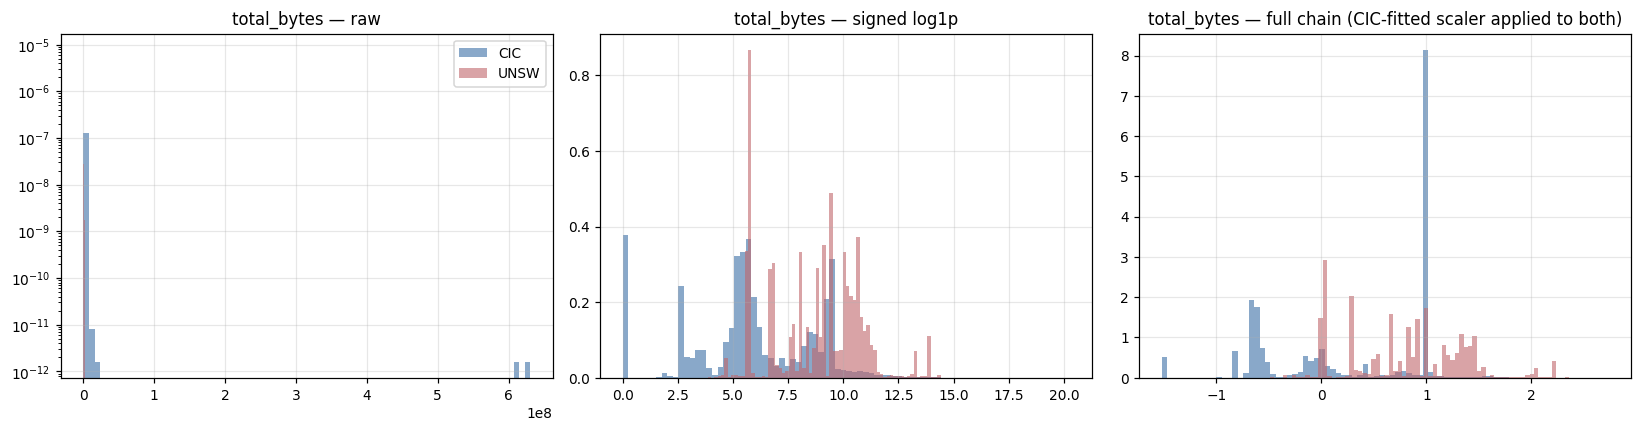

Residual shift in the right panel is genuine covariate shift and is the RQ2 signal.


In [29]:
# --- Figure: effect of the transform chain ---------------------------------
feat = "total_bytes"
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
rng = np.random.default_rng(SEED)

raw_c = cic_B[feat].to_numpy()[rng.choice(len(cic_B), 80_000, replace=False)]
raw_u = unsw_B[feat].to_numpy()[rng.choice(len(unsw_B), 80_000, replace=False)]

axes[0].hist(raw_c, bins=80, alpha=.6, density=True, label="CIC", color="#3b6ea5")
axes[0].hist(raw_u, bins=80, alpha=.6, density=True, label="UNSW", color="#c1666b")
axes[0].set_title(f"{feat} — raw"); axes[0].legend(); axes[0].set_yscale("log")

axes[1].hist(signed_log1p(raw_c), bins=80, alpha=.6, density=True, color="#3b6ea5")
axes[1].hist(signed_log1p(raw_u), bins=80, alpha=.6, density=True, color="#c1666b")
axes[1].set_title(f"{feat} — signed log1p")

pre = PREPROC[("cic", "B")]
i = FSB_NUMERIC.index(feat)
tc = pre.named_transformers_["num"].transform(cic_B[FSB_NUMERIC].iloc[:80_000])[:, i]
tu = pre.named_transformers_["num"].transform(unsw_B[FSB_NUMERIC].iloc[:80_000])[:, i]
axes[2].hist(tc, bins=80, alpha=.6, density=True, color="#3b6ea5")
axes[2].hist(tu, bins=80, alpha=.6, density=True, color="#c1666b")
axes[2].set_title(f"{feat} — full chain (CIC-fitted scaler applied to both)")

for ax in axes:
    ax.grid(alpha=.3)
plt.tight_layout()
plt.savefig(FIGURES / "fig01_transform_effect.png")
plt.show()
print("Residual shift in the right panel is genuine covariate shift and is the RQ2 signal.")


This cell quantifies how far apart the two datasets remain after harmonisation.
A per feature distance is computed between the CIC and UNSW distributions.
Large remaining distances predict which features will fail to transfer.
This table becomes direct evidence in the RQ2 discussion.

,feature,wasserstein_logscale,cic_median,unsw_median
1,src_bytes,1.2255,74.000,1920.000
10,src_bytes_per_s,1.1401,641.130,106260.980
4,dst_pkts,1.1019,2.000,18.000
15,total_pkts,1.0943,4.000,34.000
11,dst_bytes_per_s,1.0690,1182.530,161366.323
3,src_pkts,1.0674,2.000,16.000
13,dst_pkts_per_s,1.0189,16.215,1078.930
14,total_bytes,0.9994,288.000,9202.000
5,src_mean_pkt,0.9817,40.000,73.000
12,src_pkts_per_s,0.8989,27.034,1225.179


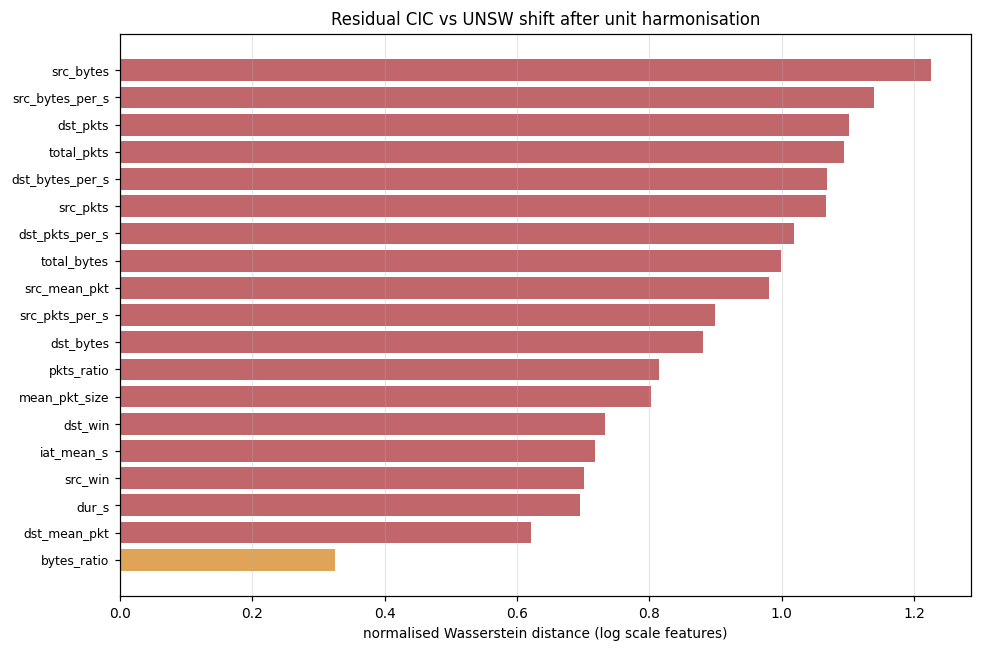

In [30]:
# --- Residual covariate shift after harmonisation ---------------------------
from scipy.stats import wasserstein_distance

rng = np.random.default_rng(SEED)
ic = rng.choice(len(cic_B), 60_000, replace=False)
iu = rng.choice(len(unsw_B), 60_000, replace=False)

rows = []
for f in FSB_NUMERIC:
    a = signed_log1p(cic_B[f].to_numpy()[ic])
    b = signed_log1p(unsw_B[f].to_numpy()[iu])
    sd = np.std(np.concatenate([a, b])) or 1.0
    rows.append({"feature": f,
                 "wasserstein_logscale": round(wasserstein_distance(a, b) / sd, 4),
                 "cic_median": round(float(np.median(cic_B[f].to_numpy()[ic])), 3),
                 "unsw_median": round(float(np.median(unsw_B[f].to_numpy()[iu])), 3)})
shift = pd.DataFrame(rows).sort_values("wasserstein_logscale", ascending=False)
display(shift)
shift.to_csv(REPORTS / "covariate_shift_cic_unsw.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 6))
s = shift.iloc[::-1]
ax.barh(range(len(s)), s.wasserstein_logscale,
        color=["#c1666b" if v > 0.5 else "#e0a458" if v > 0.25 else "#3b6ea5"
               for v in s.wasserstein_logscale])
ax.set_yticks(range(len(s))); ax.set_yticklabels(s.feature, fontsize=8)
ax.set_xlabel("normalised Wasserstein distance (log scale features)")
ax.set_title("Residual CIC vs UNSW shift after unit harmonisation")
ax.grid(axis="x", alpha=.3)
plt.tight_layout(); plt.savefig(FIGURES / "fig02_residual_shift.png"); plt.show()
M["decisions"]["worst_shift_features"] = shift.head(5).to_dict("records")


This cell writes the manifest and prints the hand off summary.
The printed block is short enough to paste straight back into the chat.
Every number here was measured rather than assumed.
Notebook 03 begins from the files listed at the end.

In [31]:
# --- Manifest and hand-off --------------------------------------------------
M["run_finished_utc"] = datetime.now(timezone.utc).isoformat(timespec="seconds")
M["shapes"]["final"] = {k: list(v.shape) for k, v in FRAMES.items()}
(REPORTS / "run_manifest_nb02.json").write_text(json.dumps(M, indent=2, default=str))

print("=" * 76)
print("NOTEBOOK 02 SUMMARY  — paste this back into the chat")
print("=" * 76)
for ds in ["cic", "unsw", "nsl"]:
    d, dd, s = FRAMES[ds], M["decisions"]["dedup"][ds], SPLITS[ds]
    print(f"\n[{ds}]")
    print(f"  rows  {dd['start']:>10,} -> {dd['final']:>10,}  "
          f"({dd['retained_pct']}% retained)")
    print(f"  removed: {dd['start']-dd['after_exact']:,} exact dupes | "
          f"{dd['conflict_rows']:,} conflicting-label rows in {dd['conflict_groups']:,} groups")
    print(f"  features Set A       : {len(FSA[ds])} numeric + {len(CATS[ds])} categorical")
    print(f"  structural drops     : {len(M['decisions']['structural_prune'][ds])}")
    print(f"  split                : {len(s['train']):,} / {len(s['val']):,} / {len(s['test']):,}")
    print(f"  attack rate          : {100*d['y'].mean():.3f}%  "
          f"(1:{(1-d['y'].mean())/max(d['y'].mean(),1e-9):.1f})")

print(f"\n[feature_set_B]  {len(FSB_NUMERIC)} numeric + {len(FSB_CATEGORICAL)} categorical")
print(f"  excluded artefacts : {CFG['unsw_artefact_features']}")
print(f"  worst residual shift: "
      f"{[(r['feature'], r['wasserstein_logscale']) for r in M['decisions']['worst_shift_features']]}")
print(f"\n[cic_daydisjoint] unseen classes in test: "
      f"{SPLITS['cic_daydisjoint']['unseen_classes']}")
print(f"\n[verification] {len(checks)} checks, "
      f"{sum(1 for c in checks if c['result']=='PASS')} passed")
print("\n[top-10 features by mean rank (training only)]")
print("  " + ", ".join(M["decisions"]["feature_ranking"]["top15"][:10]))
print("\n" + "=" * 76)
print("\nFiles for Notebook 03:")
for p in sorted(PROCESSED.glob("*")):
    print(f"  {p.name:36s} {p.stat().st_size/1e6:8.1f} MB")


NOTEBOOK 02 SUMMARY  — paste this back into the chat

[cic]
  rows   2,830,743 ->  2,516,119  (88.89% retained)
  removed: 256,479 exact dupes | 1,466 conflicting-label rows in 719 groups
  features Set A       : 62 numeric + 1 categorical
  structural drops     : 15
  split                : 1,435,855 / 358,964 / 448,705
  attack rate          : 15.122%  (1:5.6)

[unsw]
  rows   2,540,047 ->  2,017,170  (79.41% retained)
  removed: 512,025 exact dupes | 900 conflicting-label rows in 450 groups
  features Set A       : 39 numeric + 3 categorical
  structural drops     : 0
  split                : 1,290,632 / 322,659 / 403,323
  attack rate          : 3.869%  (1:24.8)

[nsl]
  rows     148,517 ->    147,692  (99.44% retained)
  removed: 0 exact dupes | 210 conflicting-label rows in 98 groups
  features Set A       : 37 numeric + 3 categorical
  structural drops     : 1
  split                : 100,240 / 25,060 / 22,392
  attack rate          : 47.953%  (1:1.1)

[feature_set_B]  19 numeri